In [2]:
from pathlib import Path
import sys
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from sklearn.feature_extraction.text import CountVectorizer

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'ypipe').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from ypipe import config

SEED = 42
np.random.seed(SEED)
MIN_VIEW_COUNT = 1000  # ngưỡng sàng lọc ban đầu để tránh so sánh title của video mới có rất ít lượt xem
MIN_GROUP_VIDEOS = 5  # mỗi nhóm cao/thấp trong một thể loại cần ít nhất 5 video để tránh nhóm quá nhỏ
N_TOP_CATEGORIES = 6  # giới hạn số thể loại trên heatmap để biểu đồ còn đọc được
config.DATA.mkdir(parents=True, exist_ok=True)
_previous_con = globals().get('con')
if _previous_con is not None:
    try:
        _previous_con.close()
    except Exception:
        pass
class _NotebookQueryResult:
    def __init__(self, frame):
        self._frame = frame
    def df(self):
        return self._frame.copy()
    def fetchdf(self):
        return self._frame.copy()
    def fetchone(self):
        if self._frame.empty:
            return None
        return tuple(self._frame.iloc[0].tolist())
    def fetchall(self):
        return list(self._frame.itertuples(index=False, name=None))

class _NotebookReadOnlyDB:
    """Run each read query on a short-lived connection to avoid retaining a file lock."""
    def __init__(self, path):
        self.path = Path(path)
    def execute(self, sql, parameters=None):
        if not self.path.exists():
            if sql.strip().lower() == 'show tables':
                return _NotebookQueryResult(pd.DataFrame({'name': pd.Series(dtype='object')}))
            return _NotebookQueryResult(pd.DataFrame())
        db = duckdb.connect(str(self.path), read_only=True)
        try:
            result = db.execute(sql) if parameters is None else db.execute(sql, parameters)
            frame = result.fetchdf()
        finally:
            db.close()
        return _NotebookQueryResult(frame)
    def close(self):
        # Queries already close their own connection before returning.
        return None

con = _NotebookReadOnlyDB(config.DB_PATH)
TABLES = set(con.execute('SHOW TABLES').fetchdf()['name'])
print(f'Database: {config.DB_PATH} | seed={SEED}')

Database: D:\project\bigdata\data\warehouse.duckdb | seed=42


# Hiệu suất video — Stage 5

## Câu hỏi
Video được đăng vào thời điểm nào, người tham gia mở video sau bao lâu, và những đặc điểm tiêu đề nào đi cùng mức `views_per_day` cao/thấp trong số video đã xem?

## Phương pháp
Dùng bảng `video_facts` (mỗi video một dòng) cho phân tích video. Heatmap dùng giờ đăng theo múi giờ cấu hình; độ trễ dùng sự kiện mở trong `watch_raw`. So sánh hiệu suất bằng `views_per_day` và phân vị trong cùng thể loại. Tiêu đề chỉ được so sánh khi `view_count` đạt ngưỡng `MIN_VIEW_COUNT`; các phân vị cao/thấp được xác định riêng trong từng thể loại. `view_count` là ảnh chụp tại `fetched_at`, không phải số lượt xem lúc mở video.

In [3]:
facts = con.execute('SELECT * FROM video_facts').df() if 'video_facts' in TABLES else pd.DataFrame()
raw = con.execute('SELECT video_id, watched_at FROM watch_raw').df() if 'watch_raw' in TABLES else pd.DataFrame()
if len(facts):
    facts = facts[facts['metadata_status'].eq('ok')].copy()
    facts['category_name'] = facts['category_name'].fillna('Chưa phân loại')
    facts['views_per_day'] = pd.to_numeric(facts['views_per_day'], errors='coerce')
    facts['view_count'] = pd.to_numeric(facts['view_count'], errors='coerce')
    facts['log_views_per_day'] = np.log1p(facts['views_per_day'].clip(lower=0))
    facts['category_percentile'] = facts.groupby('category_name')['views_per_day'].rank(pct=True)
    facts['category_percentile'] = facts['category_percentile'] * 100
    facts['pub_dow'] = pd.to_numeric(facts['pub_dow'], errors='coerce')
    facts['pub_hour'] = pd.to_numeric(facts['pub_hour'], errors='coerce')
    category_order = (facts.groupby('category_name')['video_id'].nunique()
                      .sort_values(ascending=False).head(N_TOP_CATEGORIES).index.tolist())
else:
    category_order = []

if len(raw) and len(facts):
    event_delay = raw.merge(facts[['video_id','category_name','published_at']], on='video_id', how='inner')
    event_delay['watched_local'] = pd.to_datetime(event_delay['watched_at'], utc=True).dt.tz_convert(config.TZ)
    # video_facts.published_at đã là giờ địa phương không kèm timezone.
    event_delay['published_local'] = pd.to_datetime(event_delay['published_at']).dt.tz_localize(config.TZ)
    event_delay['delay_days'] = (event_delay['watched_local'] - event_delay['published_local']).dt.total_seconds() / 86400
    negative_delay_count = int((event_delay['delay_days'] < 0).sum())
    event_delay = event_delay[event_delay['delay_days'] >= 0].copy()
else:
    event_delay = pd.DataFrame(columns=['video_id','category_name','delay_days'])
    negative_delay_count = 0

print(f'Video có metadata thành công: {len(facts):,}; video qua ngưỡng view: {int((facts.view_count >= MIN_VIEW_COUNT).sum()) if len(facts) else 0:,}')
print(f'Sự kiện có độ trễ âm bị loại khỏi biểu đồ: {negative_delay_count:,}')

Video có metadata thành công: 89,044; video qua ngưỡng view: 86,652
Sự kiện có độ trễ âm bị loại khỏi biểu đồ: 2,056


## Kết quả: thời điểm đăng và độ trễ mở video
Heatmap đếm video duy nhất theo thứ và giờ đăng, tách theo các thể loại phổ biến nhất. Biểu đồ độ trễ tính theo lượt mở; vì vậy một video được mở nhiều lần có thể đóng góp nhiều sự kiện.

C:\Users\miin\AppData\Local\Temp\ipykernel_14248\1171969279.py:17: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


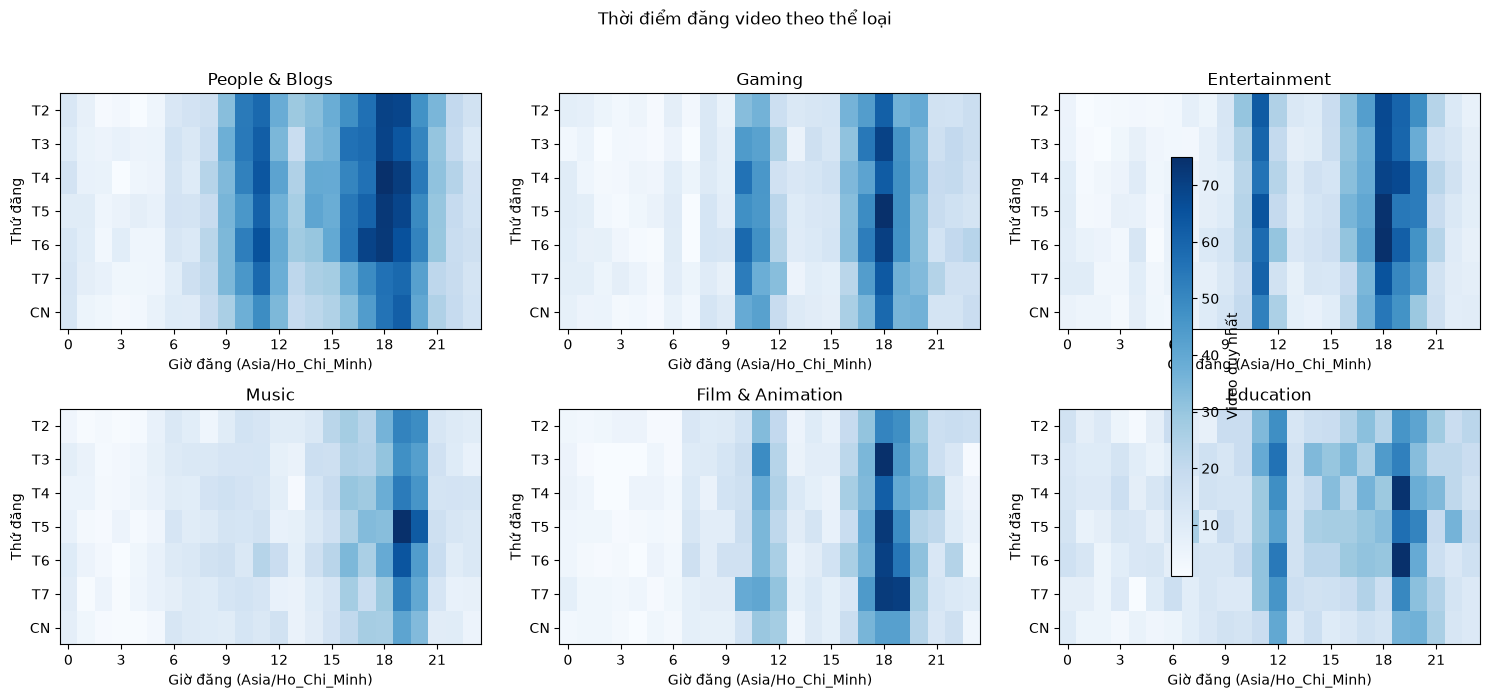

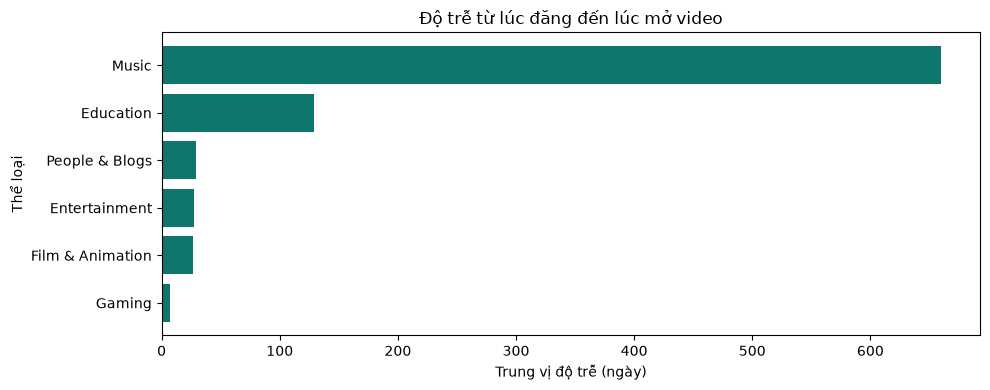

,Số lượt mở,Trung vị (ngày)
category_name,,
People & Blogs,39813,29.303517
Gaming,24984,6.819204
Music,24349,659.783153
Entertainment,20234,27.839075
Education,5183,129.231388
Film & Animation,4943,26.799764


In [7]:
day_labels = ['T2','T3','T4','T5','T6','T7','CN']
if len(facts) and category_order:
    ncols = min(3, len(category_order)); nrows = int(np.ceil(len(category_order) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 3.4*nrows), squeeze=False)
    image = None
    for ax, category in zip(axes.flat, category_order):
        subset = facts[(facts['category_name']==category) & facts['pub_hour'].notna() & facts['pub_dow'].notna()]
        heat = (subset.groupby(['pub_dow','pub_hour'])['video_id'].nunique()
                .unstack(fill_value=0).reindex(index=range(7),columns=range(24),fill_value=0))
        image = ax.imshow(heat.values, aspect='auto', cmap='Blues')
        ax.set_title(str(category))
        ax.set_xticks(range(0,24,3)); ax.set_xlabel('Giờ đăng (' + config.TZ + ')')
        ax.set_yticks(range(7)); ax.set_yticklabels(day_labels); ax.set_ylabel('Thứ đăng')
    for ax in axes.flat[len(category_order):]: ax.remove()
    if image is not None: fig.colorbar(image, ax=axes.ravel().tolist(), label='Video duy nhất', shrink=0.8)
    fig.suptitle('Thời điểm đăng video theo thể loại', y=1.02)
    plt.tight_layout(); plt.show()
else:
    print('Chưa có video hợp lệ có thời điểm đăng để vẽ heatmap.')

if len(event_delay):
    delay_summary = (event_delay.groupby('category_name')['delay_days']
                    .agg(n_events='size', median_days='median').sort_values('n_events',ascending=False).head(N_TOP_CATEGORIES))
    fig, ax = plt.subplots(figsize=(10,4))
    plot_delay = delay_summary.sort_values('median_days')
    ax.barh(plot_delay.index, plot_delay['median_days'], color='#0f766e')
    ax.set_title('Độ trễ từ lúc đăng đến lúc mở video')
    ax.set_xlabel('Trung vị độ trễ (ngày)'); ax.set_ylabel('Thể loại')
    plt.tight_layout(); plt.show()
    display(delay_summary.rename(columns={'n_events':'Số lượt mở','median_days':'Trung vị (ngày)'}))
else:
    print('Chưa có sự kiện đủ timestamp để tính độ trễ.')

## Kết quả: views/ngày và đặc điểm tiêu đề
Dùng log(1 + `views_per_day`) để giảm ảnh hưởng của đuôi phân phối dài. Phân vị được tính trong từng thể loại. Với phần tiêu đề, notebook so sánh nhóm 25% cao nhất và 25% thấp nhất trong mỗi thể loại; thể loại chỉ được đưa vào khi mỗi phía có ít nhất `MIN_GROUP_VIDEOS` video.

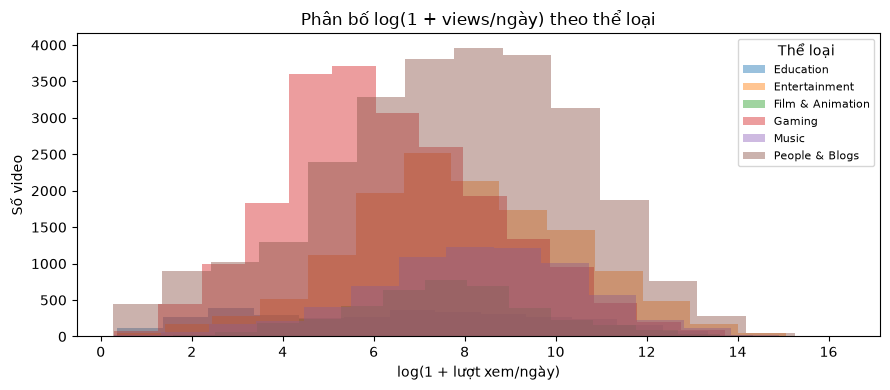

,Video,Trung vị views/ngày
category_name,,
Pets & Animals,299,12620.231866
Comedy,492,10020.337360
Travel & Events,746,4670.568924
Music,7022,4043.824978
Howto & Style,1155,3666.233596
Sports,3027,3307.525043
People & Blogs,27071,2601.616334
Entertainment,13567,2394.490088
Film & Animation,3937,2006.661189


,Đặc trưng tiêu đề,n cao,n thấp,Trung vị nhóm cao,Trung vị nhóm thấp,p-value
0,title_len_chars,22259,19911,52.000000,69.000000,0.000000e+00
1,title_len_words,22259,19911,9.000000,13.000000,0.000000e+00
3,has_number,22259,19911,0.000000,0.000000,5.033670e-230
6,has_emoji,22259,19911,0.000000,0.000000,5.450170e-198
8,has_hashtag,22259,19911,0.000000,0.000000,1.985548e-104
2,upper_ratio,22220,19906,0.166667,0.208955,2.084187e-62
7,has_brackets,22259,19911,0.000000,0.000000,6.239823e-22
4,has_question,22259,19911,0.000000,0.000000,6.548338e-14
5,has_exclaim,22259,19911,0.000000,0.000000,2.888228e-01


,Từ/cụm từ,log-odds (cao so với thấp)
0,horiz,5.966649
1,muốn hẹn,-5.901423
2,horiz vi,5.800229
3,tng,-5.706548
4,lập trình,-5.603630
5,mobile top,-5.547905
6,acq,5.538276
7,mỹ tập,-5.458024
8,hò hoàn,-5.458024
9,top tướng,-5.393277


In [8]:
eligible = facts[(facts['view_count'] >= MIN_VIEW_COUNT) & facts['views_per_day'].notna()].copy() if len(facts) else pd.DataFrame()
if len(eligible):
    eligible['log_views_per_day'] = np.log1p(eligible['views_per_day'].clip(lower=0))
    eligible['performance_group'] = np.select(
        [eligible['category_percentile'] >= 75, eligible['category_percentile'] <= 25],
        ['cao','thap'], default='giua')
    plot_dist = eligible[eligible['category_name'].isin(category_order)]
    if len(plot_dist):
        fig, ax = plt.subplots(figsize=(9,4))
        for category, group in plot_dist.groupby('category_name'):
            ax.hist(group['log_views_per_day'].dropna(), bins=15, alpha=0.45, label=str(category))
        ax.set_title('Phân bố log(1 + views/ngày) theo thể loại')
        ax.set_xlabel('log(1 + lượt xem/ngày)'); ax.set_ylabel('Số video')
        ax.legend(title='Thể loại', fontsize=8); plt.tight_layout(); plt.show()
    percentile_summary = (eligible.groupby('category_name')
        .agg(n_videos=('video_id','nunique'), median_views_per_day=('views_per_day','median'))
        .sort_values('median_views_per_day',ascending=False))
    display(percentile_summary.rename(columns={'n_videos':'Video','median_views_per_day':'Trung vị views/ngày'}))
else:
    eligible = pd.DataFrame()
    print(f'Không có video đủ MIN_VIEW_COUNT={MIN_VIEW_COUNT} và views_per_day hợp lệ.')

if len(eligible):
    group_sizes = eligible[eligible['performance_group'].isin(['cao','thap'])].groupby(['category_name','performance_group']).size().unstack(fill_value=0)
    valid_categories = [cat for cat in group_sizes.index
                        if group_sizes.loc[cat].get('cao',0) >= MIN_GROUP_VIDEOS
                        and group_sizes.loc[cat].get('thap',0) >= MIN_GROUP_VIDEOS]
    comparison = eligible[eligible['category_name'].isin(valid_categories) & eligible['performance_group'].isin(['cao','thap'])].copy()
else:
    comparison = pd.DataFrame(); valid_categories = []

numeric_features = ['title_len_chars','title_len_words','upper_ratio','has_number','has_question','has_exclaim','has_emoji','has_brackets','has_hashtag']
tests = []
if len(comparison):
    for feature in numeric_features:
        high = pd.to_numeric(comparison.loc[comparison.performance_group=='cao', feature], errors='coerce').dropna()
        low = pd.to_numeric(comparison.loc[comparison.performance_group=='thap', feature], errors='coerce').dropna()
        if len(high) and len(low):
            result = mannwhitneyu(high, low, alternative='two-sided')
            tests.append({'Đặc trưng tiêu đề':feature,'n cao':len(high),'n thấp':len(low),
                          'Trung vị nhóm cao':high.median(),'Trung vị nhóm thấp':low.median(),'p-value':result.pvalue})
test_table = pd.DataFrame(tests).sort_values('p-value') if tests else pd.DataFrame()
if len(test_table): display(test_table)
else: print('Chưa đủ MIN_GROUP_VIDEOS ở cả hai phía trong một thể loại để kiểm định.')

# Log-odds có làm trơn để tìm từ/cụm từ phân biệt hai nhóm; đây là mô tả, không phải tác động của tiêu đề.
distinctive_terms = pd.DataFrame()
if len(comparison) >= 4 and comparison['title'].fillna('').str.strip().ne('').sum() >= 4:
    vectorizer = CountVectorizer(ngram_range=(1,2), min_df=2, max_features=8000,
        token_pattern=r'(?u)\b[^\W\d_]{2,}\b', lowercase=True)
    try:
        X = vectorizer.fit_transform(comparison['title'].fillna('').astype(str))
        high_counts = np.asarray(X[comparison['performance_group'].eq('cao').to_numpy()].sum(axis=0)).ravel()
        low_counts = np.asarray(X[comparison['performance_group'].eq('thap').to_numpy()].sum(axis=0)).ravel()
        alpha = 0.5; vocab_size = max(X.shape[1],1)
        high_log_rate = np.log((high_counts+alpha)/(high_counts.sum()+alpha*vocab_size))
        low_log_rate = np.log((low_counts+alpha)/(low_counts.sum()+alpha*vocab_size))
        terms = np.asarray(vectorizer.get_feature_names_out())
        log_odds = high_log_rate-low_log_rate
        top_idx = np.argsort(np.abs(log_odds))[::-1][:20]
        distinctive_terms = pd.DataFrame({'Từ/cụm từ':terms[top_idx], 'log-odds (cao so với thấp)':log_odds[top_idx]})
        display(distinctive_terms)
    except ValueError:
        print('Không đủ từ lặp lại để lập bảng log-odds.')
else:
    print('Chưa đủ video title thuộc hai nhóm để tính log-odds.')

## Insight
Diễn giải phân bố và chênh lệch giữa nhóm cao/thấp như liên hệ mô tả. `views_per_day` chuẩn hóa tuổi video theo phép chia đơn giản, nhưng không loại hết khác biệt về thời điểm đăng, độ phủ hoặc thay đổi theo thời gian. Các p-value là thăm dò trên nhiều đặc trưng, cần đọc cùng kích thước mẫu và trung vị.

## Hạn chế
Phân tích chỉ bao gồm video có trong Takeout và metadata thành công; video không còn khả dụng có thể làm lệch mẫu. `view_count` là ảnh chụp API tại `fetched_at`, không phải số view tại thời điểm mở. Độ trễ âm bị loại khỏi biểu đồ và được đếm riêng. So sánh tiêu đề không chứng minh tiêu đề gây ra lượt xem cao; log-odds đếm token theo âm tiết và không tách từ tiếng Việt. Ngưỡng 1.000 view và tối thiểu 5 video mỗi phía là giả định thăm dò, cần kiểm tra độ nhạy trước khi kết luận.

In [9]:
# Đóng connection để pipeline notebook có thể ghi DuckDB sau khi chạy notebook.
if 'con' in globals() and con is not None:
    con.close()
    print('Đã đóng connection DuckDB; có thể chạy pipeline.')

Đã đóng connection DuckDB; có thể chạy pipeline.
